<a href="https://colab.research.google.com/github/saratyulyuova/tenge-ruble-network/blob/main/network_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tenge and Ruble in the Emerging-Market Currency Network, 2015–2026

**Author:** Sara Tyulyuova

**Research question:** How did the network position of the Kazakhstani tenge relative to the Russian ruble change after February 2022?

**H₀:** The correlation-based network distance between KZT and RUB is the same before and after 24 February 2022.
**H₁:** The distance changed (two-sided test).

## 1. Setup and data

In [1]:
!pip install -q yfinance networkx


In [2]:
import yfinance as yf          # downloads market data from Yahoo Finance
import pandas as pd            # tables (DataFrames) and time series
import numpy as np             # fast math on arrays
import matplotlib.pyplot as plt  # plots
import networkx as nx          # graphs and minimum spanning trees

print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)

pandas 2.2.3 | numpy 2.1.3 | yfinance 0.2.66


In [ ]:
tickers = ["KZT=X", "RUB=X"]   # KZT=X means: how many tenge for 1 US dollar

raw = yf.download(tickers, start="2015-08-01", end="2026-10-01", progress=False)
px = raw["Close"]              # keep only daily closing prices
px.columns = ["KZT", "RUB"]    # short readable names

px.head()


In [ ]:
print("Shape:", px.shape)                       # (rows, columns)
print("From", px.index.min().date(), "to", px.index.max().date())
print("\nMissing values:\n", px.isna().sum())
print("\nSummary:\n", px.describe().round(2))
print("\nLast 5 rows:\n", px.tail())

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

px["KZT"].plot(ax=axes[0], color="tab:blue", title="KZT per 1 USD")
px["RUB"].plot(ax=axes[1], color="tab:red", title="RUB per 1 USD")

for ax in axes:
    ax.axvline(pd.Timestamp("2015-08-20"), ls="--", color="gray")   # tenge free float
    ax.axvline(pd.Timestamp("2022-02-24"), ls="--", color="black")  # start of "post" period
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
folder = "/content/drive/MyDrive/tenge-ruble-network/data"
os.makedirs(folder, exist_ok=True)
px.to_csv(f"{folder}/kzt_rub_test.csv")
print("Saved to", folder)


In [ ]:
# name -> Yahoo Finance ticker
currencies = {
    # main subjects
    "KZT": "KZT=X", "RUB": "RUB=X",
    # commodity exporters
    "NOK": "NOK=X", "CAD": "CAD=X", "AUD": "AUDUSD=X", "BRL": "BRL=X",
    "ZAR": "ZAR=X", "CLP": "CLP=X", "COP": "COP=X", "MXN": "MXN=X",
    # Asia
    "CNY": "CNY=X", "INR": "INR=X", "IDR": "IDR=X", "KRW": "KRW=X",
    "THB": "THB=X", "MYR": "MYR=X", "PHP": "PHP=X",
    # Europe and other emerging markets
    "EUR": "EURUSD=X", "PLN": "PLN=X", "HUF": "HUF=X", "CZK": "CZK=X", "TRY": "TRY=X",
    # safe havens
    "JPY": "JPY=X", "CHF": "CHF=X",
    # optional: Central Asian neighbours (kept only if data are clean)
    "UZS": "UZS=X", "KGS": "KGS=X",
}
invert = ["EUR", "AUD"]   # quoted as USD per 1 unit -> must be flipped

factors = {"GOLD": "GC=F", "OIL": "BZ=F", "DXY": "DX-Y.NYB", "VIX": "^VIX"}

print(len(currencies), "currencies,", len(factors), "other series")

## 1.2 Full sample: ~25 currencies, gold and external factors

Currencies are quoted as units per 1 USD. EUR and AUD are quoted the other way (USD per unit), so they are inverted.
External factors: Brent oil, US dollar index (DXY) and the VIX volatility index.

In [ ]:
all_tickers = list(currencies.values()) + list(factors.values())
raw = yf.download(all_tickers, start="2015-08-01", end="2026-10-01", progress=False)["Close"]

# rename columns from tickers to our short names
ticker_to_name = {t: n for n, t in {**currencies, **factors}.items()}
raw = raw.rename(columns=ticker_to_name)

# which series failed completely?
failed = [c for c in raw.columns if raw[c].isna().all()]
print("Shape:", raw.shape)
print("Failed downloads:", failed if failed else "none")

In [ ]:
prices = raw[list(currencies) + ["GOLD"]].copy()     # currencies + gold
fac = raw[["OIL", "DXY", "VIX"]].copy()               # external factors

for c in invert:
    prices[c] = 1 / prices[c]                         # now EUR, AUD = units per 1 USD

print(prices[["EUR", "AUD"]].tail(3))


In [ ]:
period = prices.loc["2015-09-01":]   # our study period

check = pd.DataFrame({
    "first":       period.bfill().iloc[0].round(3),                    # first value
    "last":        period.ffill().iloc[-1].round(3),                   # last value
    "missing_%":   (period.isna().mean() * 100).round(1),              # share of empty days
    "no_change_%": ((period.diff() == 0).mean() * 100).round(1),       # share of days with zero change
    "big_jumps":   (np.log(period).diff().abs() > 0.10).sum(),         # days with >10% move
})
check.sort_values("missing_%", ascending=False)


In [ ]:
jumps = np.log(period).diff().abs()
for c in check.index[check["big_jumps"] > 0]:
    print(c, list(jumps.index[jumps[c] > 0.10].date))

In [ ]:
(period / period.bfill().iloc[0]).plot(subplots=True, layout=(7, 4), figsize=(16, 18),
                                       sharex=True, legend=True, lw=0.8)
plt.tight_layout(); plt.show()

**Exclusion rule.** A currency is excluded if (a) more than 5% of days are missing,
or (b) the rate does not change on more than 20% of days (a peg or stale data).
Jumps above 10% are checked against known events; data errors are reported.

In [ ]:
fac_period = fac.loc["2015-09-01":]
print((fac_period.isna().mean() * 100).round(1))
fac_period.plot(subplots=True, figsize=(10, 6), sharex=True); plt.show()

In [ ]:
# Step 4: split into currencies and factors, flip EUR and AUD
prices = raw[list(currencies) + ["GOLD"]].copy()
fac = raw[["OIL", "DXY", "VIX"]].copy()
for c in ["EUR", "AUD"]:
    prices[c] = 1 / prices[c]

# Step 6 (for now): no extra exclusions yet, KGS is already removed
excluded = {}
prices_clean = prices.drop(columns=list(excluded))

print("prices_clean:", prices_clean.shape, "| fac:", fac.shape)
print(prices_clean[["EUR", "AUD"]].tail(2))

In [ ]:
period = prices.loc["2015-09-01":]

check = pd.DataFrame({
    "first":       period.bfill().iloc[0].round(3),
    "last":        period.ffill().iloc[-1].round(3),
    "missing_%":   (period.isna().mean() * 100).round(1),
    "no_change_%": ((period.diff() == 0).mean() * 100).round(1),
    "big_jumps":   (np.log(period).diff().abs() > 0.10).sum(),
})
check.sort_values("missing_%", ascending=False)

In [ ]:
jumps = np.log(period).diff().abs()
for c in ["RUB", "NOK", "ZAR", "COP", "TRY", "CLP", "PHP", "UZS", "KZT"]:
    dates = list(jumps.index[jumps[c] > 0.10].date)
    print(c, dates)

In [ ]:
def clean_spikes(p, thr=0.10):
    """Remove one-day spikes that immediately reverse (data errors)."""
    p = p.copy()
    r = np.log(p).diff()
    log = []
    for c in p.columns:
        now, nxt = r[c], r[c].shift(-1)
        spike = ((now.abs() > thr) & (nxt.abs() > thr)           # big move today AND tomorrow
                 & (np.sign(now) != np.sign(nxt))                 # in opposite directions
                 & ((now + nxt).abs() < 0.3 * now.abs()))         # tomorrow almost undoes today
        for d in p.index[spike]:
            log.append((c, d.date()))
        p.loc[spike, c] = np.nan
    return p.ffill(limit=1), log

prices_fixed, removed = clean_spikes(prices_clean)
print("Removed", len(removed), "spike days:")
for c, d in removed:
    print(" ", c, d)

In [ ]:
period2 = prices_fixed.loc["2015-09-01":]
jumps2 = np.log(period2).diff().abs()
for c in period2.columns:
    dates = list(jumps2.index[jumps2[c] > 0.10].date)
    if dates:
        print(c, dates)

In [ ]:
excluded = {
    "KGS": "no data on Yahoo Finance (ticker not found)",
    "UZS": "rate not market-determined before Sept 2017 liberalisation",
}
prices_fixed = prices_fixed.drop(columns=[c for c in excluded if c in prices_fixed.columns])
prices_fixed.to_csv(f"{folder}/raw_prices.csv")
fac.to_csv(f"{folder}/factors.csv")
print("Saved:", prices_fixed.shape[1], "series:", list(prices_fixed.columns))

In [ ]:
prices_fixed.to_csv(f"{folder}/raw_prices.csv")
print("Saved clean prices:", prices_fixed.shape)

## 1.3 Data verification: Yahoo Finance vs official rates (KZT, RUB)

In [3]:
import os
from google.colab import drive
drive.mount("/content/drive")
folder = "/content/drive/MyDrive/tenge-ruble-network/data"

prices_fixed = pd.read_csv(f"{folder}/raw_prices.csv", index_col=0, parse_dates=True)
print(prices_fixed.shape)
print(prices_fixed[["KZT", "RUB"]].tail(3))

Mounted at /content/drive
(2909, 25)
                   KZT        RUB
Date                             
2026-09-28  427.972076  81.902596
2026-09-29  424.581116  84.494904
2026-09-30  423.849579  83.745300


In [7]:
import requests, time
import xml.etree.ElementTree as ET

dates = pd.date_range("2015-09-02", "2026-09-30", freq="W-WED")   # every Wednesday
rows, failed_dates = [], []

for i, d in enumerate(dates):
    url = f"https://nationalbank.kz/rss/get_rates.cfm?fdate={d:%d.%m.%Y}"
    try:
        r = requests.get(url, timeout=20, headers={"User-Agent": "Mozilla/5.0"})
        root = ET.fromstring(r.content)
        for item in root.iter("item"):
            if item.findtext("title") == "USD":
                rate = float(item.findtext("description")) / float(item.findtext("quant"))
                rows.append((d, rate))
                break
    except Exception as e:
        failed_dates.append(d.date())
    if i % 50 == 0:
        print(f"{i} of {len(dates)} done")
    time.sleep(0.2)          # small pause so we do not overload the bank's server

kzt_off = pd.Series(dict(rows)).sort_index()
print("\nDownloaded:", len(kzt_off), "Wednesdays | failed:", len(failed_dates))
print(kzt_off.head(3)); print(kzt_off.tail(3))

0 of 579 done
50 of 579 done
100 of 579 done
150 of 579 done
200 of 579 done
250 of 579 done
300 of 579 done
350 of 579 done
400 of 579 done
450 of 579 done
500 of 579 done
550 of 579 done

Downloaded: 575 Wednesdays | failed: 0
2015-09-02    234.94
2015-09-09    245.02
2015-09-16    276.83
dtype: float64
2026-09-16    447.88
2026-09-23    447.85
2026-09-30    439.37
dtype: float64


In [6]:
import requests, io

url = ("https://www.cbr.ru/scripts/XML_dynamic.asp"
       "?date_req1=01/08/2015&date_req2=30/09/2026&VAL_NM_RQ=R01235")   # R01235 = US dollar
try:
    resp = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
    cbr_xml = resp.content
    print("Status:", resp.status_code, "| size:", len(cbr_xml), "bytes")
except Exception as e:
    print("Failed:", e)

Status: 200 | size: 328143 bytes


In [ ]:
from google.colab import files
up = files.upload()             # choose cbr_usd.xml
cbr_xml = up[list(up)[0]]

In [ ]:
cbr = pd.read_xml(io.BytesIO(cbr_xml), xpath=".//Record", parser="etree")
rub_off = pd.Series(
    cbr["Value"].astype(str).str.replace(",", ".").astype(float).values / cbr["Nominal"].values,
    index=pd.to_datetime(cbr["Date"], format="%d.%m.%Y"),
).sort_index()
print(len(rub_off), rub_off.index.min().date(), rub_off.index.max().date())
print(rub_off.tail())

In [ ]:
official = pd.concat({"KZT_official": kzt_off, "RUB_official": rub_off}, axis=1)
official.to_csv(f"{folder}/official_rates.csv")
print(official.shape)
official.tail()

In [ ]:
official = pd.read_csv(f"{folder}/official_rates.csv", index_col=0, parse_dates=True)
kzt_off, rub_off = official["KZT_official"].dropna(), official["RUB_official"].dropna()

In [ ]:
def compare(yahoo, official, name):
    both = pd.concat({"yahoo": yahoo, "official": official}, axis=1).loc["2015-09-01":].dropna()

    # 1. level difference, %
    diff = (both["yahoo"] / both["official"] - 1) * 100

    # 2. weekly log returns (Wednesday to Wednesday)
    w = both.resample("W-WED").last()
    rw = np.log(w).diff().dropna()
    corr = rw["yahoo"].corr(rw["official"])

    print(f"=== {name} ===")
    print(f"Common days: {len(both)}")
    print(f"Mean |level difference|: {diff.abs().mean():.2f}%   max: {diff.abs().max():.2f}%")
    print(f"Correlation of weekly returns: {corr:.4f}")
    print("\n10 days with the largest difference:")
    print(diff.abs().sort_values(ascending=False).head(10).round(2))

    # plots
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    both.plot(ax=ax[0], title=f"{name}: Yahoo vs official", lw=0.8)
    diff.plot(ax=ax[1], title="Difference, %", color="gray", lw=0.8)
    ax[1].axhline(0, color="black", lw=0.5)
    for a in ax:
        a.axvline(pd.Timestamp("2022-02-24"), ls="--", color="black", lw=0.8)
    plt.tight_layout(); plt.show()
    return both, diff, corr

kzt_both, kzt_diff, kzt_corr = compare(prices_fixed["KZT"], kzt_off, "KZT")
rub_both, rub_diff, rub_corr = compare(prices_fixed["RUB"], rub_off, "RUB")

In [ ]:
print("RUB around 2022-07-06:")
print(rub_both.loc["2022-07-01":"2022-07-12"].round(2))
print("\nKZT first and last values:")
print(kzt_both.iloc[[0, -1]].round(2))

**Source decision rule.** For KZT and RUB, Yahoo Finance data are kept if the correlation of weekly
returns with the official central-bank rate is above 0.95; otherwise the official rate is used.
In all cases the main result is re-estimated with official rates as a robustness check.

In [ ]:
use_official = {"KZT": kzt_corr < 0.95, "RUB": rub_corr < 0.95}
print("Use official rate instead of Yahoo:", use_official)

prices_final = prices_fixed.copy()
for c, off in [("KZT", kzt_off), ("RUB", rub_off)]:
    if use_official[c]:
        prices_final[c] = off.reindex(prices_final.index).ffill(limit=3)

prices_final.to_csv(f"{folder}/prices_final.csv")
print("Saved prices_final.csv:", prices_final.shape)

**Result.** Weekly returns from Yahoo Finance and the official rate correlate at ... for KZT
and ... for RUB. Mean absolute level difference: ...% (KZT), ...% (RUB).
Decision: ... (Yahoo / official) is used for KZT, ... for RUB.

In [8]:
kzt_off.to_csv(f"{folder}/kzt_official.csv")
print("Saved:", os.listdir(folder))

Saved: ['raw_prices.csv', 'factors.csv', 'kzt_rub_test.csv', 'official_rates.csv', 'kzt_official.csv']


In [4]:
kzt_off = pd.read_csv(f"{folder}/kzt_official.csv", index_col=0, parse_dates=True).iloc[:, 0]
print(len(kzt_off), "Wednesdays |", kzt_off.index.min().date(), "to", kzt_off.index.max().date())

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/tenge-ruble-network/data/kzt_official.csv'

In [9]:
print(os.listdir(folder))

['raw_prices.csv', 'factors.csv', 'kzt_rub_test.csv', 'official_rates.csv', 'kzt_official.csv']


In [10]:
import requests, io

url = ("https://www.cbr.ru/scripts/XML_dynamic.asp"
       "?date_req1=01/08/2015&date_req2=30/09/2026&VAL_NM_RQ=R01235")   # R01235 = US dollar
try:
    resp = requests.get(url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
    cbr_xml = resp.content
    print("Status:", resp.status_code, "| size:", len(cbr_xml), "bytes")
except Exception as e:
    print("Failed:", e)

Status: 200 | size: 328143 bytes


In [11]:
cbr = pd.read_xml(io.BytesIO(cbr_xml), xpath=".//Record", parser="etree")
rub_off = pd.Series(
    cbr["Value"].astype(str).str.replace(",", ".").astype(float).values / cbr["Nominal"].values,
    index=pd.to_datetime(cbr["Date"], format="%d.%m.%Y"),
).sort_index()
print(len(rub_off), rub_off.index.min().date(), rub_off.index.max().date())
print(rub_off.tail())

2758 2015-08-01 2026-09-30
Date
2026-09-24    84.3969
2026-09-25    84.9057
2026-09-26    84.3414
2026-09-29    84.4075
2026-09-30    84.4283
dtype: float64


In [12]:
official = pd.concat({"KZT_official": kzt_off, "RUB_official": rub_off}, axis=1)
official.to_csv(f"{folder}/official_rates.csv")
print("Saved:", official.shape)

Saved: (2786, 2)


=== KZT ===
Common days: 574
Mean |level difference|: 0.61%   max: 4.07%
Correlation of weekly returns: 0.9352

10 days with the largest difference, %:
2015-09-23    4.07
2026-07-01    3.63
2026-07-08    3.61
2026-07-22    3.55
2026-09-16    3.54
2026-09-30    3.53
2026-09-23    3.48
2026-08-26    3.46
2026-08-05    3.41
2026-09-09    3.38
dtype: float64


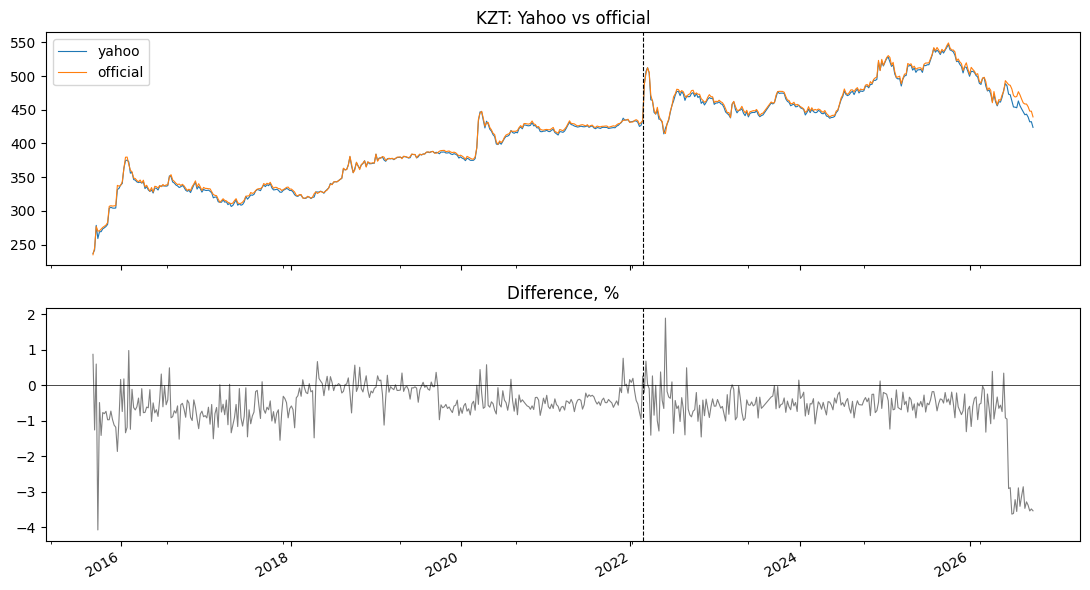

=== RUB ===
Common days: 2183
Mean |level difference|: 0.64%   max: 19.49%
Correlation of weekly returns: 0.8165

10 days with the largest difference, %:
Date
2022-03-10    19.49
2022-03-02    18.24
2022-03-01    12.20
2022-03-11    10.87
2022-07-06     8.47
2022-04-22     7.79
2022-04-21     7.34
2022-04-13     7.17
2022-05-26     7.13
2023-02-03     7.12
dtype: float64


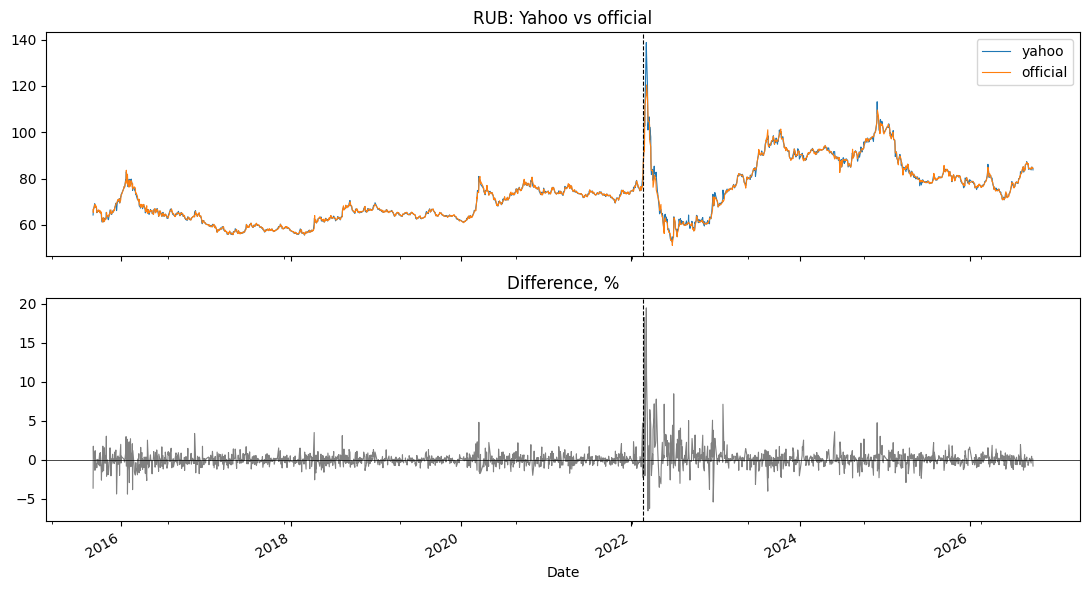

In [13]:
def compare(yahoo, official, name):
    both = pd.concat({"yahoo": yahoo, "official": official}, axis=1).loc["2015-09-01":].dropna()
    diff = (both["yahoo"] / both["official"] - 1) * 100
    w = both.resample("W-WED").last()
    rw = np.log(w).diff().dropna()
    corr = rw["yahoo"].corr(rw["official"])

    print(f"=== {name} ===")
    print(f"Common days: {len(both)}")
    print(f"Mean |level difference|: {diff.abs().mean():.2f}%   max: {diff.abs().max():.2f}%")
    print(f"Correlation of weekly returns: {corr:.4f}")
    print("\n10 days with the largest difference, %:")
    print(diff.abs().sort_values(ascending=False).head(10).round(2))

    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    both.plot(ax=ax[0], title=f"{name}: Yahoo vs official", lw=0.8)
    diff.plot(ax=ax[1], title="Difference, %", color="gray", lw=0.8)
    ax[1].axhline(0, color="black", lw=0.5)
    for a in ax:
        a.axvline(pd.Timestamp("2022-02-24"), ls="--", color="black", lw=0.8)
    plt.tight_layout(); plt.show()
    return both, diff, corr

kzt_both, kzt_diff, kzt_corr = compare(prices_fixed["KZT"], kzt_off, "KZT")
rub_both, rub_diff, rub_corr = compare(prices_fixed["RUB"], rub_off, "RUB")

In [14]:
print(rub_both.loc["2022-07-01":"2022-07-12"].round(2))

            yahoo  official
Date                       
2022-07-01  54.84     52.51
2022-07-05  54.50     55.09
2022-07-06  63.47     58.51
2022-07-07  63.51     62.91
2022-07-08  63.04     63.14
2022-07-12  60.92     61.30


In [15]:
use_official = {"KZT": kzt_corr < 0.95, "RUB": rub_corr < 0.95}
print("Use official rate instead of Yahoo:", use_official)

prices_final = prices_fixed.copy()
for c, off in [("KZT", kzt_off), ("RUB", rub_off)]:
    if use_official[c]:
        prices_final[c] = off.reindex(prices_final.index).ffill(limit=3)

prices_final.to_csv(f"{folder}/prices_final.csv")
print("Saved prices_final.csv:", prices_final.shape)

Use official rate instead of Yahoo: {'KZT': np.True_, 'RUB': np.True_}
Saved prices_final.csv: (2909, 25)
